# 03 — Sources, the sky and the noise budget

The SNR equation of notebook 01 has three kinds of terms: the source, the sky, and the detector.
This notebook shows how to describe each, and how to see which one limits you.

In this notebook:
1. sources: blackbody, power law, flat, your own arrays, lines, magnitudes in other bands,
2. the sky: `plot_sky()`, grey versus dark time with `Sky(scale=...)`,
3. the noise budget: `plot_rates()` and `plot_noise_budget()`,
4. reads: `n_exp`, `reads_needed()` and saturation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

***
## 1. Sources

`Source.blackbody(teff, mag, band, system)`, `Source.powerlaw(alpha, mag, band, system)` with
$F_\nu \propto \nu^{\alpha}$, `Source.flat(mag)` and `Source.from_arrays(wavelength_nm, flux, ...)`.
The band is the one the magnitude is quoted in; the default system is Vega, and `system="AB"` is
there for transients and AGN. `magnitude(band)` integrates the same spectrum over another band.

In [2]:
sources = {
    "G dwarf, V=15": Source.blackbody(5800, 15, "V"),
    "M dwarf, V=15": Source.blackbody(3300, 15, "V"),
    "afterglow, R=15 (AB)": Source.powerlaw(-0.7, 15, "R", system="AB"),
    "flat F_nu, V=15 (AB)": Source.flat(15, "V"),
}
for label, s in sources.items():
    print(f"{label:22s} {s.describe():45s}  J = {s.magnitude('J'):5.2f}  V(AB) = {s.magnitude('V', 'AB'):5.2f}")

G dwarf, V=15          blackbody 5800 K, V=15.00 (Vega)               J = 13.85  V(AB) = 15.00
M dwarf, V=15          blackbody 3300 K, V=15.00 (Vega)               J = 11.94  V(AB) = 15.00
afterglow, R=15 (AB)   powerlaw alpha=-0.7, R=15.00 (AB)              J = 14.51  V(AB) = 15.12
flat F_nu, V=15 (AB)   flat fnu, V=15.00 (AB)                         J = 15.00  V(AB) = 15.00


Any `(wavelength_nm, flux)` pair works. `flux_unit="flam"` means the array is proportional to
$F_\lambda$ in whatever unit and the magnitude sets the scale; `"fnu"` for an $F_\nu$ array; and
`"W/m2/nm"` for an absolute spectrum, in which case the magnitude is derived rather than given.
Gaussian lines are added with `add_line` and averaged over each resel, so the equivalent width is
preserved: a 0.05 nm wide line with a 30% core on a 0.36 nm resel appears as a resel-wide dip of
about 10%.

user spectrum, I=16.00 (Vega)


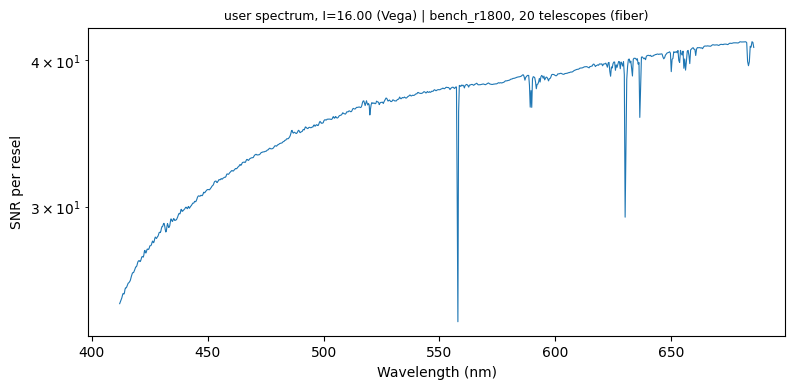

In [3]:
wl = np.linspace(380, 1800, 3000)
flux = wl**-2 * (1 + 0.5 * np.exp(-0.5 * ((wl - 850) / 20)**2))   # F_nu-flat continuum with a bump
user = Source.from_arrays(wl, flux, flux_unit="flam", mag=16, band="I").add_line(656.3, depth=0.3, sigma_nm=0.05)
print(user.describe())
r = LFASTETC("bench_r1800").snr(user, 900)
r.plot();

***
## 2. The sky

Sky surface brightness per resel on the ETC grid, in AB magnitudes per square arcsecond (left
axis, brighter is up), with the sky electron rate per pixel in the 18 um fiber in grey. The spikes
are airglow lines ([O I] 557.7 nm, Na D near 589 nm, [O I] 630.0 and 636.4 nm).

The bundled SkyCalc table is **grey time**: the moon is up, 45 degrees from the target, and
scattered moonlight is about 60% of the visible sky. Around 550 nm it is V ~ 20.5 mag per square
arcsecond, about a magnitude brighter than dark Kitt Peak (V ~ 21.7 to 22.0 at zenith, Neugent &
Massey 2010). Faint-end results are therefore pessimistic by a few tenths of a magnitude for dark time.

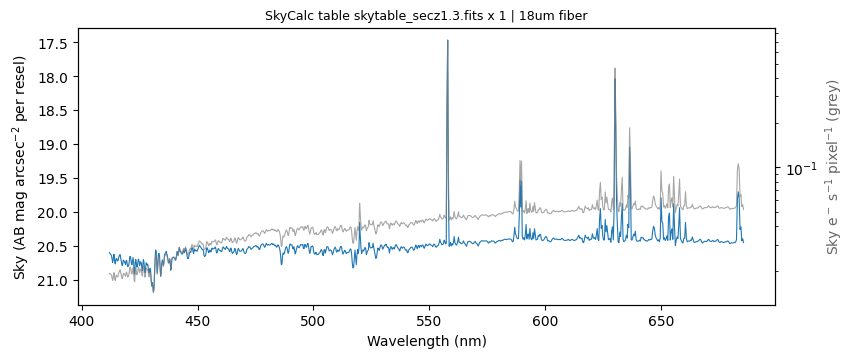

In [4]:
etc = LFASTETC("bench_r1800", n_telescopes=20)
etc.plot_sky();

`Sky(scale=0.4)` is a crude dark-time estimate. It scales the airglow lines too, which is wrong in
detail; generate a proper SkyCalc table for real planning.

> ✏️ **Before you run the next cell:** how much deeper (in magnitudes, for SNR 10 in 15 minutes) is dark time than the bundled grey sky for a G star? Write your guess down (or put it in the room poll), then run.

In [5]:
gstar = Source.blackbody(5800, 0, "V")
for label, sky in (("grey (bundled)", Sky()), ("dark (x0.4)", Sky(scale=0.4))):
    e = LFASTETC("bench_r1800", n_telescopes=20, sky=sky)
    print(f"{label:15s}: V_lim(SNR=10, 900 s) = {e.limiting_magnitude(gstar, 900, 10, wavelength=(500, 650)):.2f}")

grey (bundled) : V_lim(SNR=10, 900 s) = 18.85
dark (x0.4)    : V_lim(SNR=10, 900 s) = 19.06


***
## 3. The noise budget

Two views of the same budget. `plot_rates` shows star, sky and dark electrons per pixel per second;
`plot_noise_budget` shows the fraction of the variance each term contributes for this exposure.
For a V = 15 star in 600 s the star dominates almost everywhere and the sky takes over only at the
bright airglow lines.

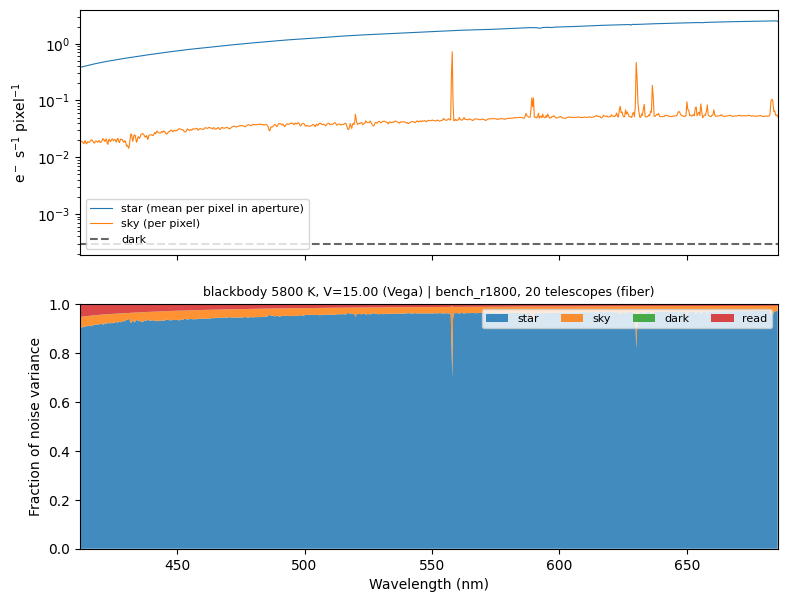

In [6]:
src = Source.blackbody(5800, 15, "V")
res = etc.snr(src, exptime=600)
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
res.plot_rates(ax=axes[0])
res.plot_noise_budget(ax=axes[1])
axes[0].set_xlabel("");

> ✏️ **Before you run the next cell:** same plot for a V = 18 star. At which wavelengths does the sky take over, and does read noise matter anywhere? Write your guess down (or put it in the room poll), then run.

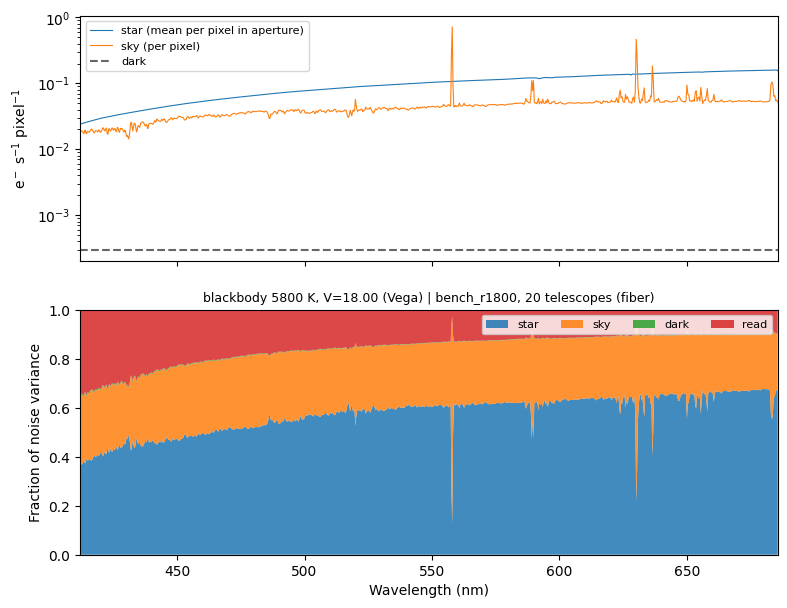

In [7]:
res18 = etc.snr(src.with_mag(18), exptime=600)
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
res18.plot_rates(ax=axes[0])
res18.plot_noise_budget(ax=axes[1])
axes[0].set_xlabel("");

> 🤖 **Ask Jupyter AI:** *Make a plot of the fraction of the variance from the star, the sky and the detector at 550 nm as a function of V magnitude from 10 to 22, in a 600 s exposure, using res.to_table() columns. Mark the magnitude where the sky overtakes the star.*

***
## 4. Reads and saturation

`n_exp` splits the exposure into reads. Each read pays the read noise again, so the cost depends on
how much read noise matters: nothing for a bright star, a lot for a faint one. `reads_needed`
returns the smallest number of reads that keeps the brightest pixel below a fraction (`margin`,
default 0.8) of the full well; `peak_e_per_pixel` and `saturated` in the result say where the limit
is.

> ✏️ **Before you run the next cell:** splitting a 600 s exposure into 10 reads: how much SNR does it cost at V = 15, and at V = 19? Write your guess down (or put it in the room poll), then run.

In [8]:
for mag in (15, 19):
    s = src.with_mag(mag)
    one = np.nanmedian(etc.snr(s, 600, n_exp=1).snr)
    ten = np.nanmedian(etc.snr(s, 600, n_exp=10).snr)
    print(f"V = {mag}: median SNR/resel {one:6.1f} in one read, {ten:6.1f} in ten ({100 * (1 - ten / one):.0f}% lower)")

V = 15: median SNR/resel   64.3 in one read,   60.4 in ten (6% lower)
V = 19: median SNR/resel    6.3 in one read,    3.6 in ten (42% lower)


In [9]:
for mag in (4, 6, 8, 10):
    s = Source.blackbody(5800, mag, "V")
    n = etc.reads_needed(s, 60)
    r = etc.snr(s, 60, n_exp=n)
    print(f"V = {mag:2d}, 60 s: {n:3d} read(s), peak {np.nanmax(r.peak_e_per_pixel):8.0f} e-/pix of {etc.instrument.full_well:.0f}, saturated: {bool(r.saturated.any())}")

V =  4, 60 s:  66 read(s), peak    69602 e-/pix of 87500, saturated: False
V =  6, 60 s:  11 read(s), peak    66187 e-/pix of 87500, saturated: False
V =  8, 60 s:   2 read(s), peak    57696 e-/pix of 87500, saturated: False
V = 10, 60 s:   1 read(s), peak    18292 e-/pix of 87500, saturated: False


***
## Summary

```python
Source.blackbody(5800, 15, "V"); Source.powerlaw(-0.7, 19, "R", system="AB"); Source.flat(15)
Source.from_arrays(wl, flux, flux_unit="flam", mag=16, band="I").add_line(656.3, 0.3, 0.05)
src.magnitude("J"); src.with_mag(18)
LFASTETC("bench_r1800", sky=Sky(scale=0.4)); etc.plot_sky()
res.plot_rates(); res.plot_noise_budget()
etc.snr(src, 600, n_exp=10); etc.reads_needed(src, 60); res.peak_e_per_pixel; res.saturated
```

Next: [04 — sensitivity maps and array scaling](04_sensitivity_maps_array_scaling.ipynb).